# NWB → YOLO26 staged dataset: step-by-step sanity checks

This notebook runs the builder in [nwb_yolo_dataset.py](nwb_yolo_dataset.py) one step at a time. Each step explains **what** it does and **why** it is done that way, then shows a plot or an assertion before you continue. The last section fine-tunes the mean-waveform checkpoint `mean_waveforms_100_spike_detection-6/weights/best.pt` on the new dataset.

Set `QUICK = True` for a run on a small fraction of the recording (~15 s once the cache exists). Set it to `False` for the full build: every chunk of the whole recording in a 70/15/15 split (~1.5 GB of PNGs). The very first run of either mode also writes the preprocessed recording to `DATASETS/nwb_pp_cache/` (~12 GB, ~2 minutes); every later run reuses it.

## How the code is organised, and why

| Step | Function in `nwb_yolo_dataset.py` | What it does |
|---|---|---|
| 1 | `prepare` → `ensure_cache` | Opens the NWB through SpikeInterface, builds the preprocessing chain, the channel order, the sorted spike list, the time split plan, and the gray lookup table. The first time, it also writes the preprocessed signal of the whole recording to a cache file (~12 GB) that every later step and build reads. |
| 6 | `run_pass1` → `_pass1_chunk` → `build_templates` | Reads 10 % of the **train** chunks to measure noise per channel. Boxes come from the NWB mean waveforms (no template is recomputed), centred on each unit's peak. |
| 8–9 | `run_pass2` → `_pass2_chunk` | Reads all planned chunks, chooses 128×128 windows, labels every sorted spike in them, and collects clean negative windows. It returns window positions and labels only, no pixels. |
| 9 | `select_items` | Balances classes and spike counts, assigns windows to the three stages, and adds 10 % negatives to each. |
| 10 | `write_dataset` | Renders each chosen window once with the image mode's lookup table, links it into every stage that uses it, and writes YOLO `.txt` labels, `data.yaml`, manifests, previews, and every setting needed to reproduce the images. |

Design decisions that apply to every step:

- **The NWB is decompressed and filtered once, into a cache.** The NWB stores the signal as gzip blocks of 195 s, and any read, even 128 samples, decompresses a whole block (~6 s). Reading it in 4 s chunks therefore decompressed each block about 50 times per pass. `ensure_cache` decompresses every block once, runs the same SpikeInterface chain over it in parallel, and keeps the int16 result as one memory-mapped file. It is reused while the NWB and the filter settings are unchanged (`meta.json` in the cache folder), so only the first build pays for it. Step 11 checks the images against the NWB chain itself.
- **Choosing windows is separate from drawing them.** Workers return positions and labels. Pixels are made at write time, once per distinct window, so stages that share windows share files (hard links), and `build(cfg, image_modes=["gray", "rgb"])` writes both encodings from the same selection.
- **Stays int16 until the very end.** SpikeInterface keeps the filtered and referenced signal in the NWB's int16 units (0.195 µV per step). The µV → gray conversion is therefore a table with one entry per possible int16 value. That table is the exact preprocessing the Edge TPU host must reproduce, with no floating-point differences.
- **One fixed mapping.** There is no per-window, per-chunk or per-channel normalization. The same voltage always becomes the same gray value, so brightness keeps a physical meaning and empty windows look empty.
- **Pass 1 is only the noise estimate.** Box geometry comes from the mean waveforms stored in the NWB units table, so pass 1 just measures noise σ per channel (on train chunks only). It takes seconds instead of reading the whole train period.

In [9]:
import csv
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

import nwb_yolo_dataset as nyd

QUICK = True
IMAGE_MODE = "gray"  # or "rgb" (R = gray, G = whitened signal, B = NEO energy); the build folder name ends in the mode

cfg = nyd.Config(image_mode=IMAGE_MODE)
if QUICK:
    cfg.time_fraction = {"train": 0.02, "val": 0.03, "test": 0.03}
    cfg.stage3_max_images = {"train": 300, "val": 100, "test": 100}
    cfg.build_stage3 = True  # small in QUICK mode, so the stage-3 code is exercised
    cfg.template_min_spikes = 20  # few chunks: at most ~80 spikes per unit are averaged
    cfg.output_root = str(Path(cfg.output_root).parent / "nwb_asinh_stages_quick")
cfg

Config(nwb_path='/Users/Zita/Documents/EGYETEM/Önlab/yolo26/Rat01_Insertion2_Depth2.nwb', output_root='/Users/Zita/Documents/EGYETEM/Önlab/yolo26/DATASETS/nwb_asinh_stages_quick', freq_min=300.0, freq_max=3000.0, filter_margin_ms=50.0, cache_dir='/Users/Zita/Documents/EGYETEM/Önlab/yolo26/DATASETS/nwb_pp_cache', window=128, gray_knee_uv=10.0, gray_vmax_uv=1000.0, image_mode='gray', whiten_radius_um=50.0, rgb_white_knee_sd=2.0, rgb_white_vmax_sd=200.0, rgb_neo_knee_uv2=100.0, rgb_neo_vmax_uv2=250000.0, train_fraction=0.7, val_fraction=0.15, split_gap_s=1.0, chunk_s=4.0, time_fraction={'train': 0.02, 'val': 0.03, 'test': 0.03}, template_before=40, template_after=40, pass1_fraction=1.0, pass1_min_chunks=20, template_max_per_chunk=10, template_min_spikes=20, box_fraction=0.25, box_min_sigma=3.0, box_min_half_width=2, center_search=5, center_min_spikes=20, dedupe_max_lag=5, dedupe_iou=None, dedupe_min_template_corr=0.9, visible_sigma=5.0, tail_fraction=0.1, edge_margin=None, edge_band=2, ne

## 1. Load recording and sorting

**What:** `prepare` reads the NWB with SpikeInterface and sets the gain to 0.195 µV per step (the NWB `conversion` field). It then builds a lazy chain: `bandpass_filter(300–3000 Hz)` → `common_reference(global median)`. This chain is the reference that deployment must reproduce. The first time, `ensure_cache` runs it once over the whole recording and stores the int16 result (`ctx["traces"]`, frames × channels in NWB column order). All later steps read from that cache. The cache is checked against the chain when it is created. It also collects all sorted spikes as (frame, class) pairs sorted by time, and plans the splits.

**Why the row order:** image rows run from the **top of the probe down**, and within each depth from left to right. That is the raw NWB channel order, and it is what the pretrained mean-waveform model saw. The opposite (bottom-up) order would show every unit upside down to that model. The probe has 4 columns, so the same column at the next depth is **4 rows** further down. That is why spikes have a comb-like texture.

**Why these class names:** class *k* is the *k*-th row of the NWB units table, named `unit_<cluster_id>`. The checkpoint used exactly these names and indices, so its class head refers to the same units.

In [10]:
ctx = nyd.prepare(cfg)
fs, num_frames = ctx["fs"], ctx["num_frames"]
print(f"uV per bit       : {ctx['uv_per_bit']}  (NWB unit field: {ctx['nwb_unit']})")
print(f"fs / frames / dur: {fs:g} Hz / {num_frames:,} / {num_frames / fs:.1f} s")
print(f"preprocessed dtype: {ctx['recording_pp'].get_dtype()}")
print(f"units / spikes   : {len(ctx['unit_ids'])} / {len(ctx['event_frames']):,}")
print(f"classes 0-4      : {ctx['class_names'][:5]}")
print(f"channel-order sha256: {ctx['order_hash'][:16]}...")
print(f"preprocessed cache: {ctx['cache_path']}  {ctx['traces'].shape} {ctx['traces'].dtype}")
assert ctx["recording_pp"].get_dtype() == np.int16
assert np.all(np.diff(ctx["event_frames"]) >= 0)
assert np.array_equal(ctx["order"], np.arange(128)), "image rows should equal the raw NWB order"

loc = ctx["locations"][ctx["order"]]
fig, ax = plt.subplots(figsize=(4, 9))
ax.scatter(loc[:, 0], loc[:, 1], s=12)
for row in range(0, 128, 8):
    ax.annotate(str(row), loc[row], fontsize=7, xytext=(3, 0), textcoords="offset points")
ax.set_title("Probe layout (numbers = image row)")
ax.set_xlabel("x (µm)"); ax.set_ylabel("depth (µm)")
plt.show()

uV per bit       : 0.195  (NWB unit field: volts)
fs / frames / dur: 20000 Hz / 47,854,800 / 2392.7 s
preprocessed dtype: int16
units / spikes   : 100 / 725,418
classes 0-4      : ['unit_14', 'unit_19', 'unit_27', 'unit_30', 'unit_31']
channel-order sha256: 2b1d4f882d5206af...
preprocessed cache: /Users/Zita/Documents/EGYETEM/Önlab/yolo26/DATASETS/nwb_pp_cache/Rat01_Insertion2_Depth2_bp300-3000_m50_cmr/traces_pp_int16.raw  (47854800, 128) int16


<Figure size 400x900 with 1 Axes>

## 2. Preprocessing check (SpikeInterface)

**What:** compares the raw signal with the filtered + referenced signal on the most active channel over 0.5 s.

**Why these filters:** the 300–3000 Hz bandpass removes slow local field potentials (below 300 Hz) and high-frequency noise, leaving the spike band. The global median reference subtracts, sample by sample, the median over all 128 channels. That removes noise every channel shares (movement, line noise) while leaving local spikes untouched. The filter runs forwards and backwards (zero phase), so spike shapes are not shifted in time. The filtered trace should be centred on 0 with spikes clearly above a noise band of roughly ±10 µV.

In [11]:
start = int(600 * fs); end = start + int(0.5 * fs)
raw = ctx["recording"].get_traces(start_frame=start, end_frame=end, return_in_uV=True)
pp = ctx["traces"][start:end] * ctx["uv_per_bit"]  # cached bandpass + CMR, in µV
ch = int(np.argmax(np.abs(pp).max(axis=0)))
t_ms = np.arange(end - start) / fs * 1000
fig, axes = plt.subplots(2, 1, figsize=(14, 5), sharex=True)
axes[0].plot(t_ms, raw[:, ch], lw=0.6); axes[0].set_title(f"raw, channel {ctx['channel_ids'][ch]}")
axes[1].plot(t_ms, pp[:, ch], lw=0.6); axes[1].set_title("bandpass 300-3000 Hz + global median CMR")
axes[1].set_xlabel("ms"); axes[1].set_ylabel("µV")
plt.show()
print(f"filtered range on this channel: {pp[:, ch].min():.0f} .. {pp[:, ch].max():.0f} µV")

<Figure size 1400x500 with 2 Axes>

filtered range on this channel: -1038 .. 294 µV


## 2b. Whitening check (SpikeInterface)

**What:** the third preprocessing step, used by the G channel of `rgb` images. `prepare` calls SpikeInterface `whiten` (mode `local`, radius 50 µm) on the cached bandpass + CMR signal. The whitening matrix is estimated on the train part only and then fixed: `whitened = traces_int16 @ W`.

**Why:** neighbouring electrodes share most of their background (correlation about 0.8 here). Whitening subtracts from each channel what its neighbours predict and scales the rest to unit noise, the same idea Kilosort uses before detection. Spikes get narrower and smaller per pixel, but the background drops more.

**Check:**
- applying the saved matrix to the cache gives exactly what the SpikeInterface whitened recording returns (this is how images are rendered, so no whitened copy of the recording is stored);
- whitened noise sd is close to 1 and the correlation between neighbouring channels is close to 0;
- in the plots, the broad bands of the bandpass + CMR image are gone in the whitened image.

In [ ]:
lut = ctx["lut"]
a = int(600 * fs); n = int(0.5 * fs)
W = ctx["whiten_W"]
block = np.asarray(ctx["traces"][a:a + n])                                  # cached bandpass + CMR, int16
white_si = ctx["recording_white"].get_traces(start_frame=a, end_frame=a + n)  # SpikeInterface whiten
white = block.astype(np.float32) @ W                                          # what the renderer does
assert np.allclose(white, white_si, atol=1e-3), "matrix product differs from SpikeInterface whiten"

o = ctx["order"]
mad = lambda z: np.median(np.abs(z - np.median(z, axis=0)), axis=0) / 0.6745
nb_corr = lambda z: np.mean([np.corrcoef(z[:, o[i]], z[:, o[i + 4]])[0, 1] for i in range(124)])  # same column, next depth
print(f"noise sd per channel: before {np.median(mad(block * ctx['uv_per_bit'])):.2f} µV, whitened {np.median(mad(white)):.2f} (want ~1)")
print(f"neighbour-channel correlation: before {nb_corr(block.astype(np.float32)):.3f}, whitened {nb_corr(white):.3f} (want ~0)")
print(f"matrix: {W.shape}, non-zero entries per channel (median) {int(np.median((W != 0).sum(axis=0)))}")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
s0 = 2000
axes[0].imshow(lut[block[s0:s0 + 256, o].T.astype(np.int32) + 32768], cmap="gray", vmin=0, vmax=255, aspect="auto")
axes[0].set_title("bandpass + CMR (gray curve)")
g = nyd.asinh_curve(white[s0:s0 + 256, o].T, cfg.rgb_white_knee_sd, cfg.rgb_white_vmax_sd)
axes[1].imshow(np.rint((g + 1) * 127.5), cmap="gray", vmin=0, vmax=255, aspect="auto")
axes[1].set_title("whitened (G channel curve)")
for ax in axes:
    ax.set_xlabel("sample"); ax.set_ylabel("channel (image order)")
plt.tight_layout(); 

plt.show()


noise sd per channel: before 6.65 µV, whitened 0.95 (want ~1)
neighbour-channel correlation: before 0.826, whitened 0.057 (want ~0)
matrix: (128, 128), non-zero entries per channel (median) 9


<Figure size 1600x500 with 2 Axes>

## 3. Fixed µV → gray mapping

**What:** `gray = 127.5·(1 + asinh(v/knee) / asinh(vmax/knee))` with knee = 10 µV and vmax = 1000 µV. Zero maps to gray 128, negative values go darker, positive values lighter.

**Why asinh:** the noise is about 5 µV, but spikes range from about 35 µV to over 600 µV.
- A linear scale fits only one of these. A narrow range such as ±50 µV saturates large spikes into identical black blobs, erasing the shape that distinguishes units. A wide range such as ±600 µV squeezes small spikes into a few gray levels.
- asinh is linear below the knee (about 2σ), so noise gets a constant, modest texture. Above the knee it is logarithmic, so every spike from 30 to ~930 µV (the largest unit here) keeps a distinct, unclipped shape.
- **The knee is the main contrast setting.** A larger knee makes the background flatter. A smaller one makes weak spikes and noise more prominent.
- **Big spikes are compressed in µV, but not in ratio.** Above ~30 µV one gray level is always ~3.8 % of the amplitude (≈ 4 µV at 100 µV, ≈ 11 µV at 300 µV). Amplitude *ratios* between units and between channels of one spike are therefore kept. The limit for the largest units is the 8-bit rounding, not the curve.

**`image_mode = "rgb"`:** R = the gray image, and the other two channels are different *views* of the signal, not other curves of the same value:
- **G** = the whitened signal (step 2b), mapped with the same asinh formula in noise units (knee 2 sd, vmax 200 sd). Background that neighbouring electrodes share is removed, so spikes stand on a flat background.
- **B** = the Teager–Kaiser (NEO) energy x[t]² − x[t−1]·x[t+1] in µV², asinh-mapped from 0 (knee 100 µV², vmax 250 000 µV²). It is unsigned and large only for fast, large deflections, so it is a classic spike-detection feature.

G and B are computed from the int16 signal at render time. The lookup table covers only R, and B needs one extra sample on each side of the window. YOLO's first convolution takes 3 channels either way.


In [ ]:
lut = ctx["lut"]
uv_axis = np.arange(-32768, 32768) * ctx["uv_per_bit"]
sel = np.abs(uv_axis) <= 1100
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(uv_axis[sel], lut[sel], label=f"asinh knee={cfg.gray_knee_uv} µV, vmax={cfg.gray_vmax_uv} µV")
lin = np.rint((np.clip(uv_axis[sel], -50, 50) / 50 + 1) * 127.5)
ax.plot(uv_axis[sel], lin, "--", color="gray", label="old linear ±50 µV")
ax.axvspan(-5, 5, color="gray", alpha=0.2, label="±1σ noise (~5 µV)")
ax.set_xlabel("µV"); ax.set_ylabel("gray"); ax.legend(); plt.show()
for v in (-1000, -600, -300, -100, -50, -25, -10, -5, 0, 5, 25):
    print(f"{v:>5} µV -> {lut[int(round(v / ctx['uv_per_bit'])) + 32768]}")

# Resolution of the asinh curve: µV per gray level and relative step at typical trough sizes.
r = lut
for v in (50, 100, 300, 600, 930):
    i = int(round(-v / ctx["uv_per_bit"])) + 32768
    step = np.argmax(r[:i][::-1] != r[i]) * ctx["uv_per_bit"]  # µV until the gray value changes
    print(f"trough {v:4d} µV: one gray level ≈ {step:5.1f} µV ({100 * step / v:.1f} %)")


## 4. Encodings side by side on real windows

**What:** the same four 128×128 windows rendered with the three current encodings (the three channels of `rgb` mode). Red triangles mark sorted spike times.
- **asinh (gray / R):** the fixed µV curve from step 3 (knee `gray_knee_uv`, vmax `gray_vmax_uv`).
- **whitened (G):** SpikeInterface `whiten` (step 2b), asinh with knee `rgb_white_knee_sd` sd.
- **TEO (B):** Teager–Kaiser energy `x[t]² − x[t−1]·x[t+1]` in µV², negatives set to 0, asinh with knee `rgb_neo_knee_uv2`.

**What to look for:** all three use fixed curves, so empty windows should stay flat (gray for asinh and whitened, black for TEO). Spikes should be visible in all three; whitened removes the broad bands shared across channels, TEO lights up only the fast spike core.

In [ ]:
from dataclasses import replace

a = int(600 * fs)
ev = ctx["event_frames"]; ev = ev[(ev >= a) & (ev < a + int(2 * fs))] - a
enc_rgb = nyd.make_encoder(replace(cfg, image_mode="rgb"), ctx)

encodings = [  # (title, RGB channel, colormap)
    (f"asinh (knee {cfg.gray_knee_uv} µV)", 0, "gray"),
    (f"whitened (asinh, knee {cfg.rgb_white_knee_sd} sd)", 1, "gray"),
    (f"TEO energy (asinh, knee {cfg.rgb_neo_knee_uv2:g} µV²)", 2, "magma"),
]
starts = [2000, 15000, 26000, 9000]
fig, axes = plt.subplots(len(starts), len(encodings), figsize=(4 * len(encodings), 16), squeeze=False)
for i, s0 in enumerate(starts):
    img = nyd.window_image(ctx, a + s0, enc=enc_rgb)  # (channels, 128, 3)
    e = ev[(ev >= s0) & (ev < s0 + 128)] - s0
    for j, (name, ch, cmap) in enumerate(encodings):
        axes[i, j].imshow(img[..., ch], cmap=cmap, vmin=0, vmax=255, interpolation="nearest")
        axes[i, j].plot(e, np.full(len(e), -2), "rv", ms=4, clip_on=False)
        axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
        if i == 0:
            axes[i, j].set_title(name, fontsize=10)
    axes[i, 0].set_ylabel(f"{len(e)} sorted spikes")
plt.tight_layout(); plt.show()

## 5. Chronological split plan

**What:** the recording is cut by time into train (70 %) → 1 s gap → val (15 %) → 1 s gap → test (15 %). Each split is divided into 4 s chunks. The full build uses **all** of them (`time_fraction` = 1.0); QUICK mode uses a few percent.

**Why split by time:** windows overlap, and neighbouring spikes in a burst are near-copies of each other. A random split would put almost identical crops in train and test and inflate the scores. A time split with a gap keeps every window, and every burst it belongs to, inside one split. Testing on the end of the recording also reflects deployment, where the model meets future data, including electrode drift.

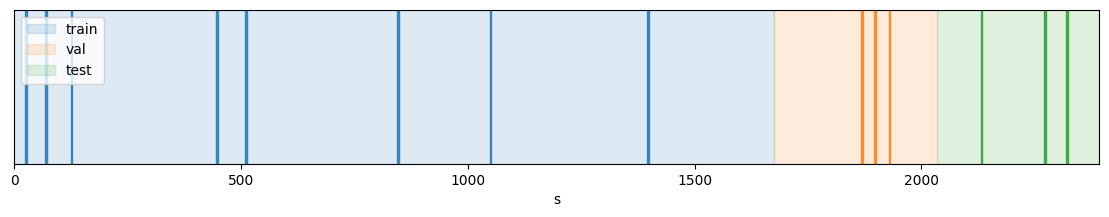

train:     0.0- 1674.9 s, 8 chunks of 4.0 s
val  :  1675.9- 2033.8 s, 3 chunks of 4.0 s
test :  2034.8- 2392.7 s, 3 chunks of 4.0 s


In [6]:
colors = {"train": "tab:blue", "val": "tab:orange", "test": "tab:green"}
fig, ax = plt.subplots(figsize=(14, 2))
for split, (s, e) in ctx["intervals"].items():
    ax.axvspan(s / fs, e / fs, color=colors[split], alpha=0.15, label=split)
    for cs, ce in ctx["chunks"][split]:
        ax.axvspan(cs / fs, ce / fs, color=colors[split], alpha=0.8)
ax.set_xlim(0, num_frames / fs); ax.set_yticks([]); ax.set_xlabel("s"); ax.legend(loc="upper left")
plt.show()

gap = int(cfg.split_gap_s * fs)
assert ctx["intervals"]["val"][0] - ctx["intervals"]["train"][1] >= gap
assert ctx["intervals"]["test"][0] - ctx["intervals"]["val"][1] >= gap
for split, (s, e) in ctx["intervals"].items():
    assert all(s <= cs and ce <= e for cs, ce in ctx["chunks"][split]), split
    print(f"{split:5s}: {s / fs:7.1f}-{e / fs:7.1f} s, {len(ctx['chunks'][split])} chunks of {cfg.chunk_s} s")

## 6. Pass 1: noise σ per channel and templates averaged from the recording (train chunks)

**What:** each worker reads one train chunk from the cache and returns:
- each channel's noise σ, computed as MAD/0.6745 (median absolute deviation);
- for every unit, the sum of up to `template_max_per_chunk` (10) of its 81-sample snippets (40 before and 40 after the sorted spike time, all 128 channels), spread evenly over the chunk;
- the unit's peak-channel trace ±5 samples, used only for the timing fallback.

The main process takes the median σ over chunks and divides each unit's snippet sum by its count to get the template. All train chunks are read (`pass1_fraction` = 1.0); it takes about 20 s from the cache.

**Why MAD:** σ estimated from the median ignores spikes, while a plain standard deviation would be inflated by them. σ sets the lower limit of each box (3σ), the "weak spike" statistic and the negative rule. Expect roughly 4–6 µV, fairly flat across channels. A spike in this plot points to a noisy or broken channel.

**Why recompute templates:** the labels must describe what is in the images, and the images come from this preprocessing. Compared with the stored `mean_waveform_all_channels_filt` (another filter), the recomputed templates:
- peak at the sorted spike time (the stored ones are about 1 sample late for ~70 % of units);
- have a different peak channel for 11 % of units (by 4 rows: same probe column, next depth);
- have about the same amplitude.

**Fallback:** units with fewer than `template_min_spikes` (50) averaged spikes use the stored waveform, moved to the peak time measured on their peak channel. In the full build that is 2 units; QUICK mode reads only a few chunks, so more units fall back there.

In [ ]:
nyd.run_pass1(cfg, ctx)
sigma = ctx["sigma"]
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(sigma, ".-"); ax.set_xlabel("image row"); ax.set_ylabel("noise σ (µV)")
ax.set_title(f"median {np.median(sigma):.2f} µV, min {sigma.min():.2f}, max {sigma.max():.2f}")
plt.show()
src = ctx["template_source"]
print("template sources:", {s: src.count(s) for s in set(src)})
print("units on the stored fallback:", [ctx["class_names"][k] for k, s in enumerate(src) if s != "recomputed"])
print("spikes averaged per unit: min", int(ctx["template_spikes"].min()), "median", int(np.median(ctx["template_spikes"])))
print("box centre offset from the sorted frame (samples):", dict(zip(*np.unique(ctx["center_dt"], return_counts=True))))

## 7. Templates and centred box geometry

**What:** for each unit, take the samples of its template (averaged from the recording, step 6) where |w| ≥ max(25 % of the peak, 3σ), limited to the connected part around the peak. The box is then **centred on the peak**: the peak row, and the peak time (sorted frame + `center_dt`, usually 0–1 samples). Its half-width and half-height are the largest distance from the peak to any of those samples, so the box is symmetric in time and rows. It is clipped only at the probe ends, and is at least 2 samples to each side. Boxes are stored as offsets from the sorted spike time (left, right) plus absolute rows (top, bottom), so they can be placed on any individual spike.

**Why each rule:**
- **Centred** means the box centre is always the spike: YOLO's centre prediction then is "where the spike is", and the box is the same shape for every spike of a unit.
- **25 % of the peak** is the same convention as your earlier dataset makers.
- **The 3σ floor** stops small units from getting huge boxes that consist mostly of noise.
- **Connected part only** stops a distant co-firing neighbour in the average from stretching the box. Because of the 4-column layout, "connected" bridges gaps of up to ±4 rows (same column, next depth).
- **The peak is searched only within ±5 samples of the spike time.** The sorter marks the trough, and an averaged template can contain a larger, later spike from a co-firing unit.

The last part of the cell compares each recomputed template with the stored NWB waveform: peak channel, peak time, box size and tail.

Check that each red box is centred on the dark trough. The red tick marks the sorted spike time (column 40). The yellow cross marks the box centre. The cyan tick marks the end of the unit's **tail**: the last sample after the trough where the peak channel is still above 10 % of the peak (or 3σ). Anchored windows are placed so the tail is always inside them.

In [ ]:
templates, boxes = ctx["templates"], ctx["boxes"]
c = cfg.template_before
show = np.linspace(0, len(templates) - 1, 12, dtype=int)
fig, axes = plt.subplots(2, 6, figsize=(18, 7))
for ax, k in zip(axes.flat, show):
    img = lut[np.clip(np.rint(templates[k] / ctx["uv_per_bit"]), -32768, 32767).astype(np.int32) + 32768]
    ax.imshow(img, cmap="gray", vmin=0, vmax=255, aspect="auto")
    left, right, y0, y1 = boxes[k]
    ax.add_patch(plt.Rectangle((c - left - 0.5, y0 - 0.5), left + right + 1, y1 - y0, fill=False, ec="red"))
    ax.axvline(c, color="red", lw=0.5, ymax=0.03)
    ax.axvline(c + ctx["tail_after"][k], color="cyan", lw=0.8, ymax=0.06)  # end of the tail
    ax.plot(c + ctx["center_dt"][k], ctx["peak_row"][k], "y+", ms=8)  # box centre = mean-waveform peak
    ax.set_title(f"{ctx['class_names'][k]} ({src[k][:6]})\n{left + right + 1}×{y1 - y0}px, "
                 f"{-templates[k].min():.0f} µV", fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

widths = boxes[:, 0] + boxes[:, 1] + 1
heights = boxes[:, 3] - boxes[:, 2]
fig, axes = plt.subplots(1, 3, figsize=(15, 3))
axes[0].hist(widths, 20); axes[0].set_title("box width (samples)")
axes[1].hist(heights, 20); axes[1].set_title("box height (rows)")
peak_amp = np.abs(templates).max(axis=(1, 2))
axes[2].hist(peak_amp / sigma[ctx["peak_row"]], 30); axes[2].set_title("template SNR (peak / σ)")
plt.show()
assert (boxes[:, :2] >= 0).all() and (boxes[:, 3] > boxes[:, 2]).all(), "every box must contain the spike frame"
assert widths.max() < cfg.window, "a box wider than the window can never be complete"

# Centred: box centre (in samples / rows) equals the mean-waveform peak, up to the probe-end clip.
centre_t = (boxes[:, 1] - boxes[:, 0]) / 2
assert np.allclose(centre_t, ctx["center_dt"]), "box not centred in time"
centre_r = (boxes[:, 2] + boxes[:, 3] - 1) / 2
clipped = (boxes[:, 2] == 0) | (boxes[:, 3] == templates.shape[1])
assert np.allclose(centre_r[~clipped], ctx["peak_row"][~clipped]), "box not centred in rows"
print(f"all boxes centred on the peak ({clipped.sum()} clipped at a probe end)")

# Recomputed (recording) vs stored (NWB) templates: same rules applied to the stored waveform.
_, b_st, r_st, _, t_st, dt_st, _ = nyd.build_templates(cfg, ctx["stored"], sigma)
rec = np.array([s_ == "recomputed" for s_ in src])
print(f"recomputed units: {rec.sum()}; vs stored waveform:")
print(f"  same peak row {np.mean(ctx['peak_row'][rec] == r_st[rec]):.0%}; peak time stored "
      f"{dict(zip(*np.unique(dt_st[rec], return_counts=True)))} -> recording {dict(zip(*np.unique(ctx['center_dt'][rec], return_counts=True)))}")
for name, new, old in (("box width", widths, b_st[:, 0] + b_st[:, 1] + 1), ("box height", heights, b_st[:, 3] - b_st[:, 2]),
                       ("tail", ctx["tail_after"], t_st)):
    d = (new - old)[rec]
    print(f"  {name:10s} recording - stored: median {np.median(d):+.0f}, p5/p95 {np.percentile(d, 5):+.0f}/{np.percentile(d, 95):+.0f}")

## 8. Pass 2 on ONE chunk, in this process

**What `_pass2_chunk` does with a chunk:**
1. Reads the chunk from the cache and converts it to σ units. No image is made here: each item holds its window position and labels, and `write_dataset` draws it later. `nyd.window_image(ctx, frame)` draws one on request.
2. **Every sorted spike is a label candidate.** Its trough on the peak row is measured only for statistics: below `visible_sigma` (5σ) it counts as *weak*. Each spike has a **box** (the label); the position that matters is the **centre** of the box.
3. **Edge rule** (`window_objects`, the labels of any window start), the same in every stage. Each picture has an invalid strip at its left and right edge, `edge_margin` samples wide = half the widest box, rounded up (16 here). What happens to a spike depends only on the column of its box centre:

   | Box centre | Treatment |
   |---|---|
   | in the valid zone, at least `edge_band` (2) from the strip border: columns 18–109 | labelled; the box is always completely inside the picture |
   | in a strip or outside the picture, at least 2 from the border: columns < 14 or ≥ 114 | never labelled, even if fully visible |
   | within 2 of the border: columns 14–17 and 110–113 | ambiguous: the window is not used |

   Windows stepped by 128 − 2·16 = 96 samples would label every spike exactly once.
4. **Stage 1 (single spike):** the spikes are ordered by box centre. For each spike, the window starts that put its centre in the valid zone *and* the centres of both neighbours (so of all other spikes) in a strip or outside form one interval [lo, hi]. Other spikes may therefore be visible in the strips, without a label.
5. **Stage 2 (1–3 spikes):** the same for groups of 2–3 consecutive spikes, all labelled together.
6. **The jitter** is one uniformly random start in [lo, hi], so a labelled spike lands anywhere in the valid zone and is not centred. After drawing, `window_objects` must return exactly the planned spikes (`plan_mismatch` must be 0).
7. **Stage 3 (only with `build_stage3`):** a sliding window with stride `stage3_stride` (64) from a random offset. Windows with an ambiguous spike, or without any label, are dropped.
8. **Negatives:** non-overlapping windows with **no sorted spike within 40 samples** (`negative_margin`) and **no sample beyond 5σ on any channel**, so unsorted spikes never appear as "nothing".

**Stages are cumulative:** stage 2 contains every stage-1 window, and stage 3 every stage-1 and stage-2 window (`select_items`).

This cell runs the worker on one chunk. It then re-checks every stage-1/2 window **independently from the event list**: for 5 other random starts in its interval, exactly its spikes must have their centre in the valid zone and no spike may be in a border band. In the pictures the dashed cyan lines are the strip borders: no box centre may lie outside them.


In [ ]:
nyd._init_worker(nyd.worker_state(cfg, ctx))
task = nyd.pass2_tasks(cfg, ctx)[0]
items, unit_total, unit_visible, counts = nyd._pass2_chunk(task)
anch = [it for it in items if it["kind"] == "anchored"]
grp = [it for it in items if it["kind"] == "group"]
tiles = [it for it in items if it["kind"] == "tile"]
negs = [it for it in items if it["kind"] == "negative"]
print(f"chunk {task[1] / fs:.1f}-{task[2] / fs:.1f} s ({task[3]}): {len(anch)} stage-1, {len(grp)} stage-2, "
      f"{len(tiles)} stage-3 windows, {len(negs)} negatives; window search {counts}")
assert counts["plan_mismatch"] == 0

for it in items:
    lab = it["labels"]
    img = nyd.window_image(ctx, it["window_start_frame"])
    assert img.shape[:2] == (128, 128) and img.dtype == np.uint8
    assert it["jitter_lo"] <= it["window_start_frame"] <= it["jitter_hi"]
    if len(lab):
        assert (lab[:, 1] >= 0).all() and (lab[:, 3] <= 128).all() and (lab[:, 1] < lab[:, 3]).all()
        assert (lab[:, 2] >= 0).all() and (lab[:, 4] <= 128).all() and (lab[:, 2] < lab[:, 4]).all()
M, BAND = ctx["edge_margin"], cfg.edge_band
for it in anch + grp + tiles:  # every label is a complete (unclipped) box with its centre in the valid zone
    full_w = boxes[it["labels"][:, 0], 0] + boxes[it["labels"][:, 0], 1] + 1
    assert np.array_equal(it["labels"][:, 3] - it["labels"][:, 1], full_w), "box clipped"
    centre = it["labels"][:, 1] + boxes[it["labels"][:, 0], 0] + ctx["center_dt"][it["labels"][:, 0]]
    assert ((centre >= M + BAND) & (centre < cfg.window - M - BAND)).all(), "label centre in an edge strip"
assert all(len(it["labels"]) == 1 for it in anch)
assert all(2 <= len(it["labels"]) <= 3 for it in grp)
assert all(len(it["labels"]) == 0 for it in negs) and all(len(it["labels"]) for it in tiles)

# Independent re-check from the event list: other starts inside each interval give the same content.
fr, cl = ctx["event_frames"], ctx["event_classes"].astype(int)
B, DT = ctx["boxes"], ctx["center_dt"]
W = cfg.window
def contents(ws):
    """(spikes centred in the valid zone, spikes centred in a border band) of the window at ws."""
    a, b = np.searchsorted(fr, [ws - 200, ws + W + 200])
    rel = fr[a:b].astype(int) + DT[cl[a:b]] - ws
    labelled = (rel >= M + BAND) & (rel < W - M - BAND)
    ambiguous = ((rel >= M - BAND) & (rel < M + BAND)) | ((rel >= W - M - BAND) & (rel < W - M + BAND))
    return int(labelled.sum()), int(ambiguous.sum())
check_rng = np.random.default_rng(3)
for it in anch + grp:
    for ws2 in check_rng.integers(it["jitter_lo"], it["jitter_hi"] + 1, 5):
        n_labelled, n_ambiguous = contents(int(ws2))
        assert n_labelled == len(it["labels"]) and n_ambiguous == 0, (it["kind"], ws2)
print(f"label checks passed; {len(anch) + len(grp)} jitter intervals re-checked at 5 random starts each")
rng = np.random.default_rng(1)
nyd.plot_items(anch, "stage-1 windows (one labelled spike, jittered)", 8, rng, ctx=ctx); plt.show()
nyd.plot_items(grp, "stage-2 windows (2-3 labelled spikes)", 8, rng, ctx=ctx); plt.show()
if tiles:
    nyd.plot_items(tiles, "stage-3 windows (sliding)", 8, rng, ctx=ctx); plt.show()
if negs:
    nyd.plot_items(negs, "negatives", 8, rng, ctx=ctx); plt.show()

## 9. Pass 2 on all chunks, then balancing

**Duplicates first:** before pass 2, `dedupe_events` drops duplicate sorter spikes. It removes the smaller unit's spike when two spikes of different units:
- lie within 5 samples,
- have boxes with IoU > 0.5,
- and come from units whose mean waveforms correlate above 0.9.

In this recording that is almost only unit_46 (class 46), which repeats about 95 % of unit_97's spikes. Different-looking units that fire together are kept.

**What:** the same worker runs on every planned chunk in parallel. `select_items` then builds the cumulative stages. There is no per-unit cap by default (`max_per_unit_count = None`); balancing waits for the classification step. If a cap is set, it applies:
- **stages 1–2:** per (split, anchor unit, label count),
- **stage 3:** per split.

Then every stage and split gets negatives: `negative_fraction` (10 %) of its images. All stages draw from one shuffled pool per split, so stage 1's negatives are a subset of stage 2's.

Stage 1 is the subset of stage 2 with exactly one label.

**Why cap per unit:** spike counts per unit range from about 100 to about 38,000. Without a cap the most active units would fill the dataset and the model would barely see the rare ones. Stage 3 isn't balanced by unit on purpose: it shows the real activity mix the model will meet.

**Why negatives in every stage:** the model also needs to learn to output nothing. Having them from stage 1 on also lets val/test measure false positives.

The per-unit *visible fraction* is a sorting-quality signal. A low value means many of that unit's spikes are too small to see. They are still labelled (weak labels), so such a unit is hard for the detector. The last check confirms that no window from one split falls within the gap of another.

window search: {'stage1_windows': 1621, 'stage2_single_with_edges': 952, 'stage2_groups': 5076, 'no_window': 14985, 'plan_mismatch': 0, 'stage3_ambiguous_dropped': 61}
pass 2 done (88 s): 1621 stage-1 windows, 6028 stage-2 windows, 327 stage-3 windows, 2887 negatives
dedupe: 0 spikes removed, per unit {}
window search (all chunks): {'stage1_windows': 1621, 'stage2_single_with_edges': 952, 'stage2_groups': 5076, 'no_window': 14985, 'plan_mismatch': 0, 'stage3_ambiguous_dropped': 61}
stage1_single_spike
  train {'images': 1102, 'negative_images': 110, 'windows_by_kind': {'anchored': 992, 'group': 0, 'tile': 0}, 'labels_per_image_mean': 0.9, 'label_count_histogram': {0: 110, 1: 992}, 'classes_present': '75/100', 'images_with_unlabelled_slivers': 0, 'weak_labels': 13}
  val   {'images': 351, 'negative_images': 35, 'windows_by_kind': {'anchored': 316, 'group': 0, 'tile': 0}, 'labels_per_image_mean': 0.9, 'label_count_histogram': {0: 35, 1: 316}, 'classes_present': '58/100', 'images_with_unl

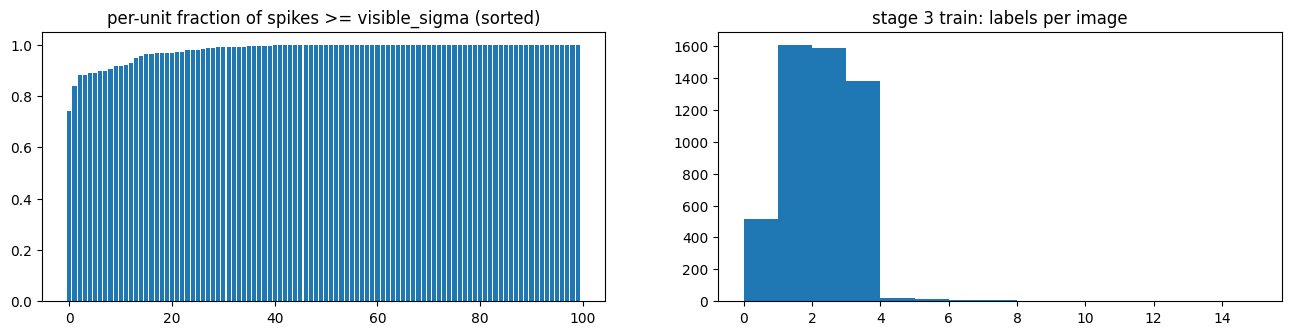

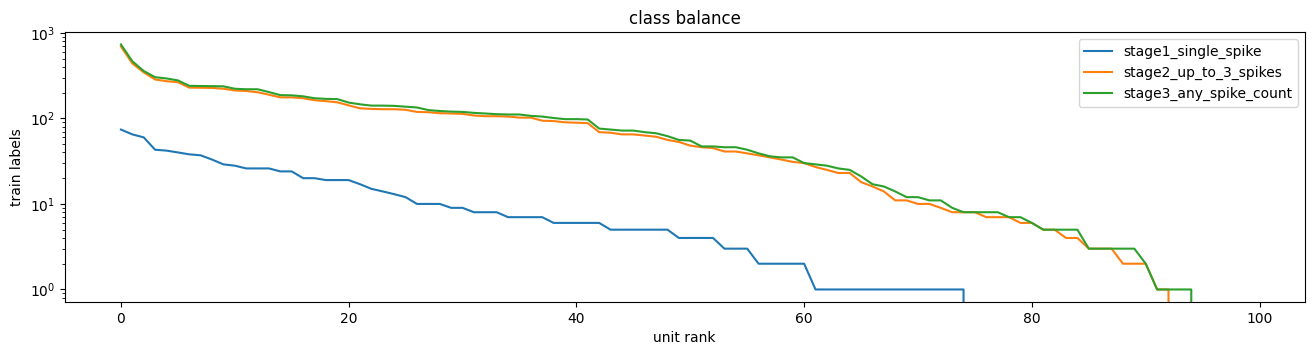

no window crosses a split boundary or gap


In [15]:
nyd.run_pass2(cfg, ctx)
print("dedupe:", ctx["dedupe"]["removed"], "spikes removed, per unit", ctx["dedupe"]["removed_per_unit"])
print("window search (all chunks):", ctx["window_counts"])
stage_items = nyd.select_items(cfg, ctx)
for name, items in stage_items.items():
    print(name)
    for split, s in nyd.stage_stats(items, len(ctx["unit_ids"])).items():
        print(f"  {split:5s}", s)

vis = ctx["unit_visible"] / np.maximum(ctx["unit_total"], 1)
fig, axes = plt.subplots(1, 2, figsize=(16, 3.5))
axes[0].bar(range(len(vis)), np.sort(vis)); axes[0].set_title("per-unit fraction of spikes >= visible_sigma (sorted)")
s3 = [len(it["labels"]) for it in stage_items["stage3_any_spike_count"] if it["split"] == "train"]
axes[1].hist(s3, bins=range(0, max(s3) + 2)); axes[1].set_title("stage 3 train: labels per image")
plt.show()

counts = np.zeros((3, len(ctx["unit_ids"])), int)
for i, name in enumerate(stage_items):
    for it in stage_items[name]:
        if it["split"] == "train":
            np.add.at(counts[i], it["labels"][:, 0], 1)
fig, ax = plt.subplots(figsize=(16, 3.5))
for i, name in enumerate(stage_items):
    ax.plot(np.sort(counts[i])[::-1], label=name)
ax.set_yscale("log"); ax.set_xlabel("unit rank"); ax.set_ylabel("train labels"); ax.legend()
ax.set_title("class balance"); plt.show()

for name, items in stage_items.items():
    ends = {sp: max((it["window_start_frame"] + 128 for it in items if it["split"] == sp), default=None) for sp in nyd.SPLITS}
    starts = {sp: min((it["window_start_frame"] for it in items if it["split"] == sp), default=None) for sp in nyd.SPLITS}
    assert starts["val"] - ends["train"] >= gap and starts["test"] - ends["val"] >= gap, name
print("no window crosses a split boundary or gap")

## 9b. Negatives and spike placement

**What:** three independent checks on the selected items.
1. **Negatives are really empty.** Each negative is re-read from the recording (not taken from the worker), and two values are measured: the largest |sample| / σ over all channels, and the distance to the nearest sorted spike. All must be below `visible_sigma` (5σ) and further than `negative_margin` (40 samples).
2. **Negative share** per stage and split should be close to `negative_fraction`.
3. **Spike positions:** the label centres of each stage should spread evenly over the valid zone (columns 18–109) instead of peaking at 64, and none may lie in the edge strips (red lines).
4. **Cumulative stages:** every image of stage 1 is in stage 2, and every image of stage 2 is in stage 3.

Look at the grid as well. Negatives should look like plain noise, with no dark blobs at the edges (a spike just outside the window would show up there).


In [ ]:
import torch
print(torch.__version__)
print(torch.__file__)
W, m = cfg.window, cfg.negative_margin
frames = ctx["event_frames"]
neg = [it for it in stage_items["stage2_up_to_3_spikes"] if it["kind"] == "negative"]
max_z, nearest = [], []
for it in neg[:: max(1, len(neg) // 300)]:
    ws = it["window_start_frame"]
    tr = ctx["traces"][ws:ws + W][:, ctx["order"]].T * ctx["uv_per_bit"]
    max_z.append(float((np.abs(tr) / ctx["sigma"][:, None]).max()))
    i, j = np.searchsorted(frames, [ws, ws + W])
    left = ws - frames[i - 1] if i > 0 else np.inf
    right = frames[j] - (ws + W - 1) if j < len(frames) else np.inf
    nearest.append(0 if j > i else min(left, right))
fig, axes = plt.subplots(1, 2, figsize=(14, 3))
axes[0].hist(max_z, 30); axes[0].axvline(cfg.visible_sigma, color="red"); axes[0].set_title("negatives: max |sample| / σ")
axes[1].hist(np.minimum(nearest, 2000), 30); axes[1].axvline(m, color="red"); axes[1].set_title("negatives: samples to nearest sorted spike")
plt.show()
assert max(max_z) < cfg.visible_sigma, "a negative contains a sample beyond visible_sigma"
assert min(nearest) > m, "a negative is too close to a sorted spike"
print(f"{len(max_z)} negatives re-checked from the recording: max |z| {max(max_z):.2f}, nearest spike {min(nearest)} samples")

for name, items in stage_items.items():
    shares = {sp: f"{sum(it['kind'] == 'negative' for it in items if it['split'] == sp)}/"
                  f"{sum(it['split'] == sp for it in items)}" for sp in nyd.SPLITS}
    print(f"{name:24s} negatives {shares}  (target {cfg.negative_fraction[name]:.0%})")

nyd.plot_items(neg, "negatives (stage 2)", 12, np.random.default_rng(2), ctx=ctx); plt.show()

# Spike positions per stage: the jitter must spread them over the image, not centre them.
fig, axes = plt.subplots(1, len(stage_items), figsize=(6 * len(stage_items), 3), squeeze=False)
for ax, (name, items) in zip(axes[0], stage_items.items()):
    centres = [(l[1] + l[3]) / 2 for it in items if it["split"] == "train" for l in it["labels"].tolist()]
    ax.hist(centres, bins=range(0, W + 1, 2)); ax.set_xlim(0, W); ax.set_title(f"{name}: label centre column")
    for xb in (ctx["edge_margin"], W - ctx["edge_margin"]):
        ax.axvline(xb, color="red")
    assert ctx["edge_margin"] + cfg.edge_band <= min(centres) and max(centres) <= W - ctx["edge_margin"] - cfg.edge_band, name
plt.show()

# Unlabelled spikes: how many images show a spike in the strips (visible, without a label).
for name, items in stage_items.items():
    pos = [it for it in items if it["kind"] != "negative"]
    print(f"{name:24s} images with an unlabelled spike in the strips: {np.mean([it['n_sliver'] > 0 for it in pos]):.0%}")

# Cumulative stages: every image of a stage is in the next one.
names = list(stage_items)
keys = {n: {(it["split"], it["window_start_frame"], it["kind"]) for it in stage_items[n]} for n in names}
for a_, b_ in zip(names, names[1:]):
    assert keys[a_] <= keys[b_], f"{a_} is not contained in {b_}"
print("stages are cumulative:", " ⊂ ".join(names))

## 9c. The `rgb` channels: whitened (G) and TEO energy (B)

**What:** a few stage-1 windows and one negative, drawn with the `rgb` encoder. This works whatever `IMAGE_MODE` is, because the encoder is made here:
- **R** = the gray asinh image;
- **G** = the whitened signal (SpikeInterface `whiten`, step 2b), asinh with knee 2 sd;
- **B** = the Teager–Kaiser (TEO / NEO) energy `e = x[t]² − x[t−1]·x[t+1]` in µV², negative values set to 0, mapped as `255·asinh(e/knee)/asinh(vmax/knee)` (knee 100 µV², vmax 250 000 µV²). Like gray, it is a fixed curve with no per-window normalisation.

**What to look for:**
- G should show the same spikes as R on a flat background: the broad light and dark bands of R are gone, spikes are narrower and fainter.
- B should be nearly black in noise and bright on the fast core of each spike (trough and steep flanks). The slow repolarisation stays dark, and weak spikes are dim.
- Unsorted spikes show in G and B too: they are real activity without a label.
- The histograms compare B in noise (negatives) with B inside spike boxes. The last plot shows the brightest B pixel per spike against the noise's 99.9th percentile (red line); nearly every spike should be to the right of it.
- The cell asserts that B never saturates inside boxes and that fewer than 2 % of spikes stay below the noise's 99.9th percentile.


In [ ]:
from dataclasses import replace

cfg_feat = replace(cfg, image_mode="rgb")
enc_feat = nyd.make_encoder(cfg_feat, ctx)
s1 = stage_items["stage1_single_spike"]
pos = [it for it in s1 if it["kind"] == "anchored" and it["split"] == "val"]
neg_s1 = [it for it in s1 if it["kind"] == "negative"]
pick_rng = np.random.default_rng(4)
pick = [pos[i] for i in pick_rng.choice(len(pos), min(4, len(pos)), replace=False)] + neg_s1[:1]

titles = ["R = gray (asinh, knee 10 µV)", "G = whitened (asinh, knee 2 sd)",
          "B = TEO energy  x[t]² − x[t−1]·x[t+1]", "RGB composite"]
fig, axes = plt.subplots(len(pick), 4, figsize=(16, 4 * len(pick)), squeeze=False)
for i, it in enumerate(pick):
    img = nyd.window_image(ctx, it["window_start_frame"], enc=enc_feat)
    for j, (data, cmap) in enumerate([(img[..., 0], "gray"), (img[..., 1], "gray"), (img[..., 2], "magma"), (img, None)]):
        ax = axes[i, j]
        ax.imshow(data, cmap=cmap, vmin=0, vmax=255, interpolation="nearest")
        for _, x0, y0, x1, y1 in it["labels"].tolist():
            ax.add_patch(plt.Rectangle((x0 - 0.5, y0 - 0.5), x1 - x0, y1 - y0, fill=False, ec="cyan", lw=1))
        ax.set_xticks([]); ax.set_yticks([])
        if i == 0:
            ax.set_title(titles[j], fontsize=10)
    axes[i, 0].set_ylabel("negative (noise only)" if it["kind"] == "negative"
                          else f"{it['split']}, {ctx['class_names'][it['anchor_class']]}", fontsize=9)
plt.tight_layout(); plt.show()

# TEO mapping curve and B values in noise vs inside spike boxes.
knee, vmax = cfg_feat.rgb_neo_knee_uv2, cfg_feat.rgb_neo_vmax_uv2
e = np.logspace(0, np.log10(vmax), 400)
curve = 255 * np.arcsinh(e / knee) / np.arcsinh(vmax / knee)
noise_b, box_b, box_peak = [], [], []
for it in s1[::2]:
    if it["kind"] not in ("anchored", "negative"):
        continue
    b = nyd.window_image(ctx, it["window_start_frame"], enc=enc_feat)[..., 2].astype(float)
    if it["kind"] == "negative":
        noise_b.append(b.ravel()[::7])
        continue
    for _, x0, y0, x1, y1 in it["labels"].tolist():
        patch = b[y0:y1, x0:x1]
        box_b.append(patch.ravel()); box_peak.append(patch.max())
noise_b, box_b, box_peak = np.concatenate(noise_b), np.concatenate(box_b), np.array(box_peak)
noise_p999 = np.percentile(noise_b, 99.9)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].semilogx(e, curve); axes[0].axvline(knee, color="gray", ls="--", label=f"knee {knee:g} µV²")
for v in (10, 25, 50, 100, 300):
    axes[0].plot(v * v, 255 * np.arcsinh(v * v / knee) / np.arcsinh(vmax / knee), "o", label=f"{v} µV step ≈ {v * v:g} µV²")
axes[0].set_xlabel("TEO energy (µV²)"); axes[0].set_ylabel("B value"); axes[0].legend(fontsize=7)
axes[0].set_title("B mapping: 255·asinh(e/knee)/asinh(vmax/knee)")
axes[1].hist(noise_b, bins=range(0, 257, 2), density=True, alpha=0.6, label="noise (negatives)")
axes[1].hist(box_b, bins=range(0, 257, 2), density=True, alpha=0.6, label="inside spike boxes")
axes[1].set_yscale("log"); axes[1].set_xlabel("B value"); axes[1].legend(); axes[1].set_title("B values: noise vs spikes")
axes[2].hist(box_peak, bins=range(0, 257, 8)); axes[2].axvline(noise_p999, color="red", label="noise 99.9th percentile")
axes[2].set_xlabel("max B inside a spike box"); axes[2].legend(); axes[2].set_title("brightest B pixel per spike")
plt.tight_layout(); plt.show()

below = np.mean(box_peak <= noise_p999)
print(f"noise B: median {np.median(noise_b):.0f}, p99 {np.percentile(noise_b, 99):.0f}, p99.9 {noise_p999:.0f}")
print(f"brightest B per spike: median {np.median(box_peak):.0f}, p10 {np.percentile(box_peak, 10):.0f}; "
      f"spikes not brighter than noise p99.9: {below:.1%}; saturated pixels in boxes: {np.mean(box_b >= 255):.3%}")
assert np.mean(box_b >= 255) < 0.001, "B saturates inside spike boxes: raise rgb_neo_vmax_uv2"
assert below < 0.02, "many spikes are invisible in B: lower rgb_neo_knee_uv2"

## 10. Write the dataset

**What:** every stage folder gets the standard Ultralytics layout:
- `images/{train,val,test}` and `labels/{train,val,test}`, with one `class cx cy w h` line per spike, normalised to 0–1,
- `data.yaml` listing the 100 class names,
- `manifest.csv` recording, for each image, the recording frame it came from and how many visible unlabelled spikes (centred in the edge strips) and weak (below 5σ) labelled spikes it contains.

The build folder also gets everything needed to recreate the images elsewhere:
- `preprocessing.json`: filter, filter margin, CMR, scale, channel-order hash, lookup-table hash, splits, package versions
- `gray_lut_int16.npy`
- `preprocessing_arrays.npz`: channel order, noise σ, bandpass coefficients
- `channel_order.csv`, `class_map.csv`, `unit_templates.npz`, `stats.json`

**Each image is drawn once.** Stage 1 is a subset of stage 2 and the stages share negatives, so a window can appear in up to three stages. It is rendered once and hard-linked into each stage folder: the same file on disk, standard Ultralytics layout, no extra space.

**Why a new timestamped folder each time:** a dataset that has been trained on is never overwritten, so results always stay traceable to the exact data.

In [16]:
root, stats = nyd.write_dataset(cfg, ctx, stage_items)
for name in stage_items:
    for split in nyd.SPLITS:
        imgs = sorted((root / name / "images" / split).glob("*.png"))
        labs = sorted((root / name / "labels" / split).glob("*.txt"))
        assert [p.stem for p in imgs] == [p.stem for p in labs], (name, split)
        vals = np.array([list(map(float, l.split()[1:])) for p in labs for l in p.read_text().splitlines()])
        if len(vals):
            assert (vals > 0).all() and (vals <= 1).all(), (name, split)
print("image/label pairing and normalised coordinates OK")
print(json.dumps(json.loads((root / "preprocessing.json").read_text())["pipeline"], indent=1)[:2500])

rendered 8857 distinct windows (101 s)
wrote /Users/Zita/Documents/EGYETEM/Önlab/yolo26/DATASETS/nwb_asinh_stages_quick/build_20261106T150111Z_gray in 110 s
image/label pairing and normalised coordinates OK
[
 {
  "step": "set_channel_gains",
  "uv_per_bit": 0.195,
  "offset": 0.0
 },
 {
  "step": "bandpass_filter",
  "freq_min": 300.0,
  "freq_max": 3000.0,
  "margin_ms": 50.0,
  "dtype": "<i2",
  "ignore_low_freq_error": false,
  "filter_mode": "sos",
  "direction": "forward-backward",
  "coefficients": "preprocessing_arrays.npz:bandpass_coeff",
  "note": "SpikeInterface default Butterworth, zero-phase; margin_ms reads extra samples on both sides (needs that much look-ahead online); output cast back to int16"
 },
 {
  "step": "common_reference",
  "reference": "global",
  "groups": null,
  "operator": "median",
  "ref_channel_ids": null,
  "local_radius": [
   30.0,
   55.0
  ],
  "min_local_neighbors": 5,
  "dtype": "<i2",
  "note": "median over all 128 channels per sample, subtract

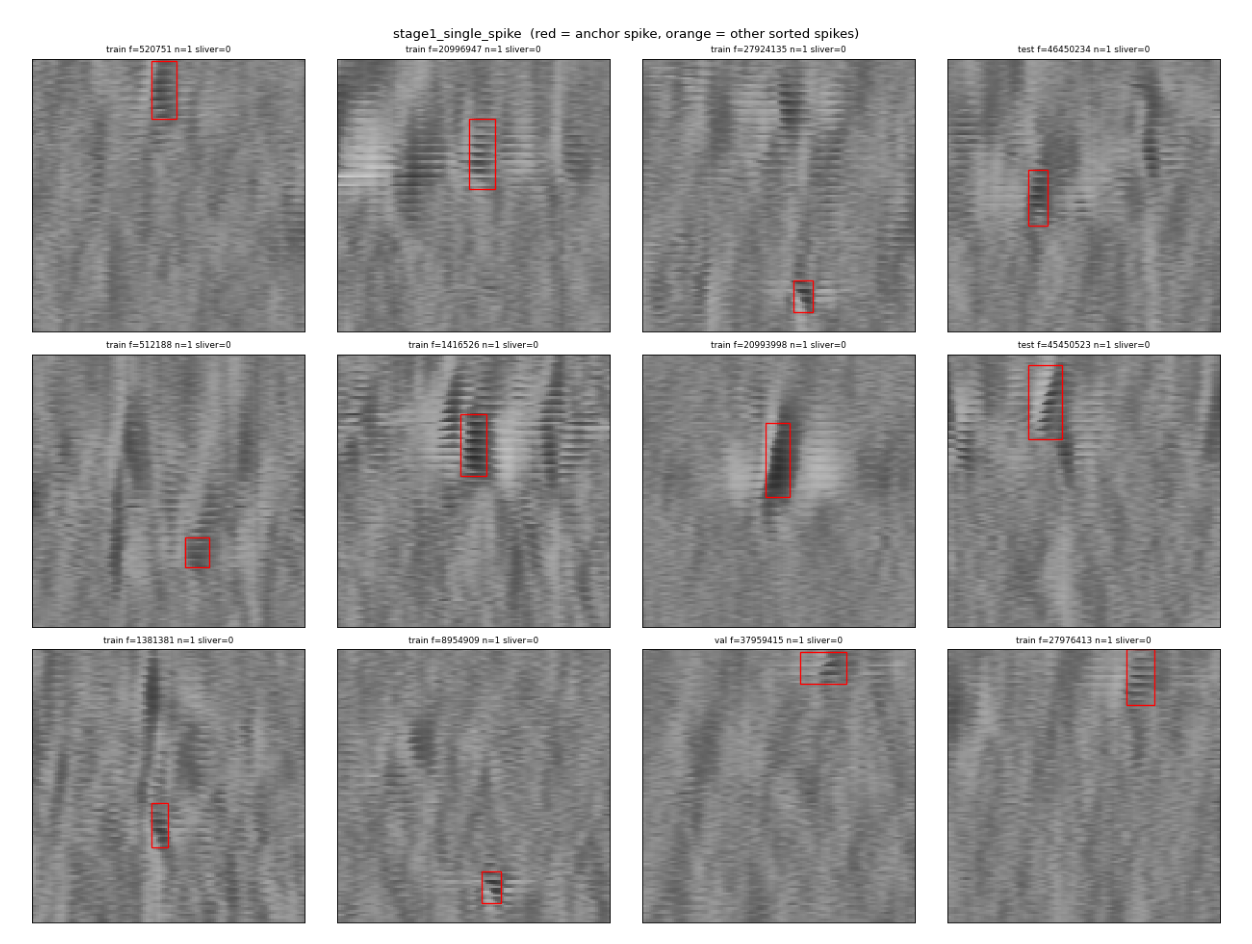

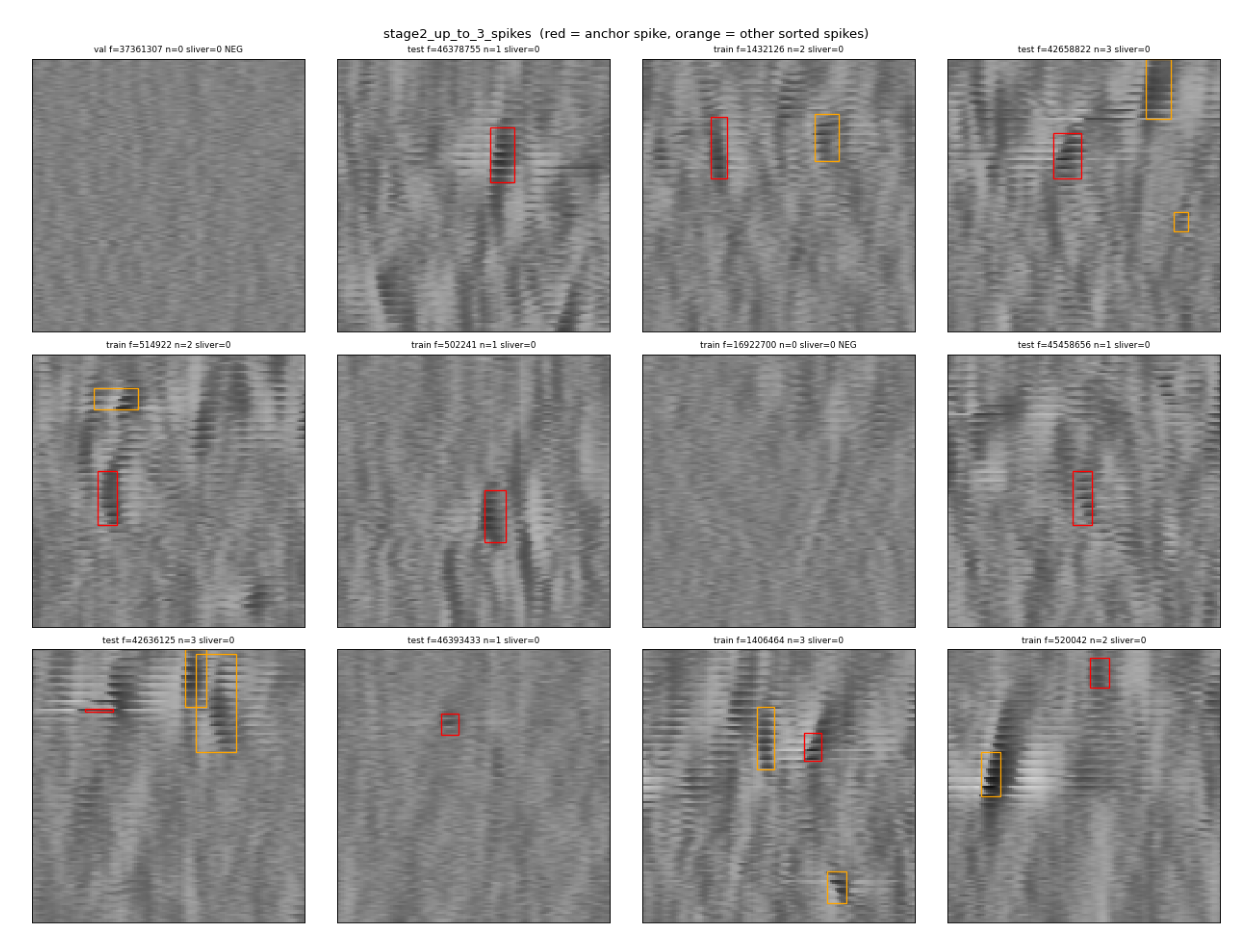

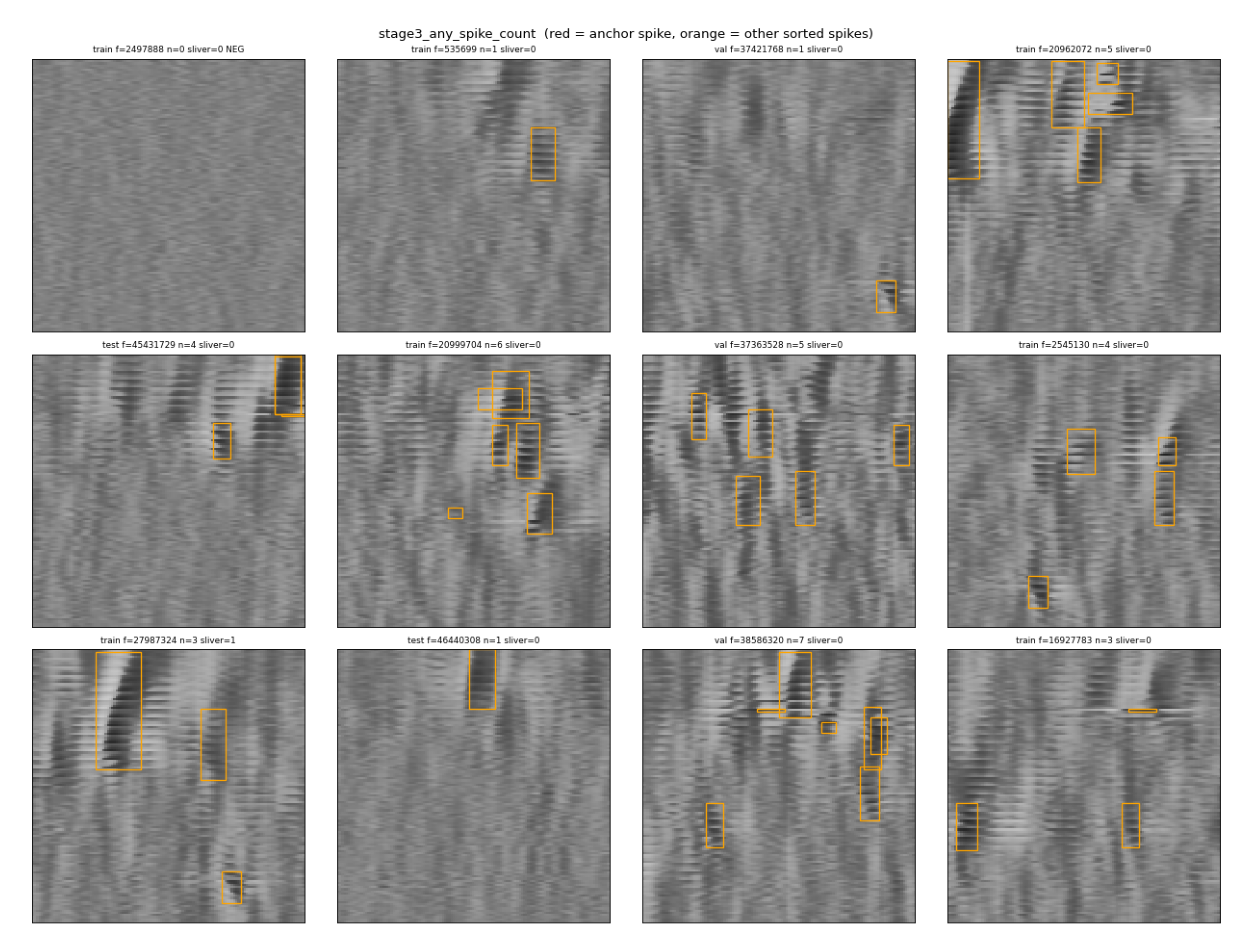

In [19]:
for name in stage_items:
    plt.figure(figsize=(16, 12)); plt.imshow(Image.open(root / f"preview_{name}.png")); plt.axis("off"); plt.show()

## 10b. Are the images good for training?

**What:** measured on the train images of every stage:
- **Brightness:** mean gray should be ~128, with almost no pixels at 0 or 255. Otherwise the fixed mapping is clipping.
- **Box contrast:** the darkest pixel inside every box should be clearly darker than −25 µV (5σ). A box over plain noise is a bad label.
- **Box size:** a very small box is hard for YOLO's stride-8 grid and is a sign of a broken template.
- **Unlabeled dark structure:** the share of strongly negative pixels (< −40 µV, ~8σ) outside every box, split into pixels *next to* a box (the tail of a large spike beyond its 25 % box) and pixels *far* from any box (spikes with no sorted unit). Both are expected to some degree. If the far share grows a lot, consider a lower `box_fraction` or check the sorting.
- **Overlap:** the share of consecutive windows that start less than 64 samples apart, i.e. near-duplicates.

In [ ]:
from scipy import ndimage

lut0 = lut  # the gray curve; in rgb mode it is the R channel
g25, g40 = (int(lut0[int(round(v / ctx["uv_per_bit"])) + 32768]) for v in (-25, -40))
for name in stage_items:
    rows = [r for r in csv.DictReader(open(root / name / "manifest.csv")) if r["split"] == "train"]
    means, sat, darkest, widths_px, heights_px, near, far = [], [], [], [], [], 0, 0
    for r in rows:
        img = np.asarray(Image.open(root / name / r["image"]))
        img = img[..., 0] if img.ndim == 3 else img
        mask = np.zeros(img.shape, bool)
        label_path = root / name / r["image"].replace("images/", "labels/").replace(".png", ".txt")
        for line in label_path.read_text().splitlines():
            _, cx, cy, bw, bh = map(float, line.split())
            x0, x1 = round((cx - bw / 2) * 128), round((cx + bw / 2) * 128)
            y0, y1 = round((cy - bh / 2) * 128), round((cy + bh / 2) * 128)
            mask[y0:y1, x0:x1] = True
            darkest.append(img[y0:y1, x0:x1].min()); widths_px.append(x1 - x0); heights_px.append(y1 - y0)
        means.append(img.mean()); sat.append(np.mean((img == 0) | (img == 255)))
        dist = ndimage.distance_transform_edt(~mask) if mask.any() else np.full(img.shape, np.inf)
        dark = (img <= g40) & ~mask
        near += int((dark & (dist <= 6)).sum()); far += int((dark & (dist > 6)).sum())
    starts = np.sort([int(r["window_start_frame"]) for r in rows])
    print(f"{name} ({len(rows)} train images)")
    print(f"  mean gray {np.mean(means):.1f}, saturated pixels {np.mean(sat):.4%}")
    print(f"  box width px p5/median/max {np.percentile(widths_px, 5):.0f}/{np.median(widths_px):.0f}/{max(widths_px)}, "
          f"height p5/median/max {np.percentile(heights_px, 5):.0f}/{np.median(heights_px):.0f}/{max(heights_px)}")
    print(f"  boxes without a trough below -25 µV: {np.mean(np.array(darkest) > g25):.2%}")
    print(f"  dark pixels outside boxes: next to a box {near / max(near + far, 1):.0%}, far from any box {far / max(near + far, 1):.0%}")
    print(f"  near-duplicate windows (<64 samples apart): {np.mean(np.diff(starts) < 64):.1%}")
    assert 120 < np.mean(means) < 136 and np.mean(sat) < 0.001, "mapping is clipping or off-centre"
    # Every sorted spike is labelled, so weak (and positive-going) spikes are expected here; only a large share is a bug.
    assert np.mean(np.array(darkest) > g25) < 0.05, "too many boxes over plain noise"


## 11. Reproduce images from the saved metadata only

**What:** rebuilds the SpikeInterface chain using only `preprocessing.json`, then applies the saved channel order and lookup table. It compares the result with the written PNGs byte for byte.

**Why:** this is the contract for the Edge TPU host. It reads the NWB directly, not the cache, so it also proves the cache equals the chain. If its preprocessing passes this test, the deployed model sees exactly the images it was trained on.

**Why the 50 ms filter margin:** the filter runs forwards and backwards, so a value near the edge of a read depends on how much signal around it was read. With SpikeInterface's default 16.7 ms margin, about 1 % of pixels differed by one step between a 128-sample read and a 4 s read. With 50 ms they are identical. For real-time use this also means the host needs 50 ms of look-ahead, or the dataset has to be rebuilt with a forward-only filter.

In [ ]:
import hashlib

import spikeinterface.full as si

meta = json.loads((root / "preprocessing.json").read_text())
steps = {s["step"]: s for s in meta["pipeline"]}
arrays = np.load(root / "preprocessing_arrays.npz")
lut_saved = np.load(root / "gray_lut_int16.npy")
order_saved = arrays["channel_order"]

rec = si.read_nwb(meta["nwb"]["path"])
rec.set_channel_gains([steps["set_channel_gains"]["uv_per_bit"]] * rec.get_num_channels())
bp = si.bandpass_filter(rec, freq_min=steps["bandpass_filter"]["freq_min"], freq_max=steps["bandpass_filter"]["freq_max"],
                        margin_ms=steps["bandpass_filter"]["margin_ms"])
assert np.allclose(np.asarray(bp._recording_segments[0].coeff), arrays["bandpass_coeff"]), "filter coefficients changed"
rec_pp = si.common_reference(bp, reference="global", operator="median")
assert hashlib.sha256(lut_saved.tobytes()).hexdigest() == steps["gray_mapping"]["lut_sha256"]
from dataclasses import replace
mode = meta["config"]["image_mode"]
enc = nyd.make_encoder(replace(cfg, image_mode=mode), ctx)  # gray: the LUT; rgb: LUT + whitening matrix + NEO
assert np.array_equal(arrays["whitening_matrix"], ctx["whiten_W"]), "saved whitening matrix differs"

for name in stage_items:
    rows = list(csv.DictReader(open(root / name / "manifest.csv")))
    for r in rows[:: max(1, len(rows) // 5)][:5]:
        ws = int(r["window_start_frame"])
        png = np.asarray(Image.open(root / name / r["image"]))
        img_lut = lut_saved[rec_pp.get_traces(start_frame=ws, end_frame=ws + 128)[:, order_saved].T.astype(np.int32) + 32768]
        assert np.array_equal(img_lut, png[..., 0] if mode == "rgb" else png), (name, r["image"], "LUT")
        x = np.ascontiguousarray(rec_pp.get_traces(start_frame=ws - 1, end_frame=ws + 129)[:, order_saved].T)
        assert np.array_equal(nyd.encode(enc, x), png), (name, r["image"], mode)
print("all sampled images reproduced exactly")

## 12. Fine-tune the mean-waveform checkpoint

**Starting point:** `mean_waveforms_100_spike_detection-6/weights/best.pt`, the model that overfit the 100 mean-waveform images. `YOLO()` needs the `.pt` file, not the `weights/` folder.

**What transfers:**
- **Class indices:** class *k* is the same unit (`unit_<cluster_id>`) in the checkpoint and in this dataset, so the 100-class head is reused as is.
- **Row order:** image rows are now in the same top-down channel order the checkpoint saw.
- **Backbone and box head:** reused in every run, including `single_cls=True`, where only the class-score layer is re-created with one class.

**What is different, so expect the first epochs to re-adapt:**
- **Brightness:** the checkpoint saw min–max normalised images, rescaled per image (background around 190, trough at 0). The new images use the fixed µV mapping (background 128).
- **Time axis:** the checkpoint saw 81 samples stretched to 128 px, so spikes were about 1.6× wider than here.
- **Noise and neighbours:** the checkpoint saw one clean averaged spike per image. Here there is noise, single-spike variability and neighbouring spikes.

The zero-shot check below measures how well the checkpoint does **before** fine-tuning. Run the `yolo26n.pt` baseline as well. If the checkpoint doesn't beat the baseline after fine-tuning, the mean-waveform pretraining isn't helping and you can drop it.

**Why stage 1 twice:** the class-agnostic run (`single_cls=True`) asks only "is there a spike, and where?" The multi-class run also asks "which of the 100 units?" If the agnostic run reaches high mAP and the multi-class run doesn't, unit identity is the hard part, not detection.

**Augmentation:**
- **`hsv_*` = 0:** brightness encodes µV, so changing it changes the signal.
- **`fliplr` = 0:** a left-right flip reverses time.
- **`flipud` = 0:** units are tied to probe depth.
- **`scale`, `degrees`, `shear` = 0:** they distort the time and channel axes.
- **Small `translate` is acceptable.** `mosaic` is acceptable for stage 3 only.

The training cells are slow, so they only run when `RUN_TRAINING = True`.

In [23]:
from ultralytics import YOLO

PRETRAINED = Path("/Users/Zita/Documents/EGYETEM/Önlab/yolo26/yolo26neuro/SAJÁT/runs/detect/spike_yolo_overfit/"
                  "mean_waveforms_100_spike_detection-6/weights/best.pt")
STAGE = "stage1_single_spike"
DATA = root / STAGE / "data.yaml"

model = YOLO(PRETRAINED)
assert len(model.names) == len(ctx["class_names"]), "checkpoint and dataset have a different number of classes"
assert [model.names[k] for k in range(len(model.names))] == ctx["class_names"], "class k is not the same unit"
print(f"checkpoint {PRETRAINED.parent.parent.name}: {len(model.names)} classes, names match the dataset")

# Zero-shot: the checkpoint on the new val images before any fine-tuning.
zero_shot = model.val(data=str(DATA), split="val", imgsz=128, batch=64, device="mps", workers=0,
                      plots=False, verbose=False, project=str(Path("runs") / "nwb_asinh"), name=f"{STAGE}_zero_shot")
print(f"zero-shot multi-class:  mAP50 {zero_shot.box.map50:.3f}  mAP50-95 {zero_shot.box.map:.3f}")
zero_shot_1 = model.val(data=str(DATA), split="val", imgsz=128, batch=64, device="mps", workers=0, single_cls=True,
                        plots=False, verbose=False, project=str(Path("runs") / "nwb_asinh"), name=f"{STAGE}_zero_shot_agnostic")
print(f"zero-shot class-agnostic: mAP50 {zero_shot_1.box.map50:.3f}  mAP50-95 {zero_shot_1.box.map:.3f}")

AttributeError: partially initialized module 'torch' has no attribute 'library' (most likely due to a circular import)

In [ ]:
common = dict(
    data=str(DATA), imgsz=128, epochs=150, batch=64, seed=42, device="mps", workers=0,
    patience=40, project=str(Path("runs") / "nwb_asinh"), val=True,
    hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, degrees=0.0, translate=0.05, scale=0.0, shear=0.0, perspective=0.0,
    flipud=0.0, fliplr=0.0, mosaic=0.0, mixup=0.0, cutmix=0.0, close_mosaic=0,
)
RUN_TRAINING = False
if RUN_TRAINING:
    # Same settings, three starting points / questions:
    YOLO(PRETRAINED).train(**common, single_cls=True, name=f"{STAGE}_pretrained_agnostic")   # can it find spikes?
    YOLO(PRETRAINED).train(**common, single_cls=False, name=f"{STAGE}_pretrained_multiclass")  # ...and tell units apart?
    YOLO("yolo26n.pt").train(**common, single_cls=False, name=f"{STAGE}_baseline_multiclass")  # does pretraining help?

## 13. Sanity check: `rgb` images on disk (µV, whitened, NEO)

**What:** shows random images of the latest `rgb` build straight from disk, with their label boxes: the RGB picture the model is trained on, then its three channels (R = µV asinh, the same as gray; G = whitened signal; B = NEO energy).

**Check:** every box centre lies between the dashed lines (the edge strips carry no labels, even where a spike is visible there); boxes sit on the spikes in every channel; R shows the full waveform, G the same spikes on a flat background, B bright blobs at the spikes; negatives are empty in all three. Change `STAGE`, `SPLIT`, `N` or `SEED` to look at other images.


In [ ]:
import csv
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

RGB_BUILD = sorted(Path("/Users/Zita/Documents/EGYETEM/Önlab/yolo26/DATASETS/nwb_asinh_stages").glob("build_*_rgb"))[-1]  # latest rgb build
STAGE, SPLIT, N, SEED = "stage1_single_spike", "val", 6, 0
MARGIN = json.loads((RGB_BUILD / "preprocessing.json").read_text())["label_policy"]["edge_margin"]
print(RGB_BUILD, "edge strips:", MARGIN, "samples")

rows_d = [r for r in csv.DictReader(open(RGB_BUILD / STAGE / "manifest.csv")) if r["split"] == SPLIT]
rng_d = np.random.default_rng(SEED)
picks = [rows_d[i] for i in rng_d.choice(len(rows_d), N, replace=False)]
titles = ["RGB (model input)", "R: µV asinh (= gray)", "G: whitened", "B: NEO energy"]

fig, axes = plt.subplots(N, 4, figsize=(14, 3.5 * N), squeeze=False)
for i, r in enumerate(picks):
    rgb = np.asarray(Image.open(RGB_BUILD / STAGE / r["image"]))
    assert rgb.shape == (128, 128, 3), rgb.shape
    label = (RGB_BUILD / STAGE / r["image"].replace("images/", "labels/", 1)).with_suffix(".txt")
    for j, img in enumerate([rgb, rgb[..., 0], rgb[..., 1], rgb[..., 2]]):
        ax = axes[i, j]
        ax.imshow(img, cmap=None if img.ndim == 3 else "gray", vmin=0, vmax=255, interpolation="nearest")
        for line in label.read_text().splitlines():
            _, cx, cy, w, h = map(float, line.split())
            ax.add_patch(plt.Rectangle(((cx - w / 2) * 128 - 0.5, (cy - h / 2) * 128 - 0.5), w * 128, h * 128,
                                       fill=False, ec="lime", lw=0.8))
        for xb in (MARGIN - 0.5, 128 - MARGIN - 0.5):  # strip borders: no label centre outside them
            ax.axvline(xb, color="cyan", lw=0.8, ls="--")
        ax.set_xticks([]); ax.set_yticks([])
        if i == 0:
            ax.set_title(titles[j])
    axes[i, 0].set_ylabel(f"{r['kind']}  f={r['window_start_frame']}  n={r['n_labels']}", fontsize=8)
fig.tight_layout()
plt.show()


In [8]:
import wandb
wandb.login()
data_gray="/Users/Zita/Documents/EGYETEM/Önlab/yolo26/DATASETS/nwb_asinh_stages/build_20261112T160151Z_gray/stage2_up_to_3_spikes/data.yaml"
data_rgb="/Users/Zita/Documents/EGYETEM/Önlab/yolo26/DATASETS/nwb_asinh_stages/build_20261112T161035Z_rgb/stage2_up_to_3_spikes/data.yaml"
from ultralytics import YOLO
model_gray= YOLO("/Users/Zita/Documents/EGYETEM/Önlab/yolo26/yolo26neuro/SAJÁT/runs/spikeyolo/stage2_up_to_3_spikes_gray_agnostic_15ep/weights/best.pt")
model_rgb= YOLO("/Users/Zita/Documents/EGYETEM/Önlab/yolo26/yolo26neuro/SAJÁT/runs/spikeyolo/stage2_up_to_3_spikes_rgb_agnostic_15ep/weights/best.pt")

#val_gray = model_gray.val(data=data_gray, split="val", imgsz=128, batch=64, device="mps", workers=0, plots=True, rect=False, verbose=True)

val_rgb = model_rgb.val(data=data_rgb, split="val", imgsz=128, batch=64, device="mps", workers=0, plots=True, rect=False, verbose=True) 

Ultralytics 8.4.84 🚀 Python-3.11.15 torch-2.11.0 MPS (Apple M3 Pro)
YOLO26n summary (fused): 122 layers, 2,375,031 parameters, 0 gradients, 5.2 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.1 ms, read: 110.2±19.2 MB/s, size: 28.3 KB)
val: Scanning /Users/Zita/Documents/EGYETEM/Önlab/yolo26/DATASETS/nwb_asinh_stages/build_20261112T161035Z_rgb/stage2_up_to_3_spikes/labels/val.cache... 33370 images, 3337 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 33370/33370 1.5Git/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 522/522 1.9it/s 4:320.5ss
                   all      33370      61335      0.955      0.875      0.916      0.753
Speed: 0.0ms preprocess, 0.3ms inference, 0.0ms loss, 0.6ms postprocess per image
Results saved to /Users/Zita/Documents/EGYETEM/Önlab/yolo26/yolo26neuro/SAJÁT/runs/detect/val-23
